# La pérdida anual como frecuencia por severidad: un primer capital por Monte Carlo

**Pregunta:** ¿Cuánto capital necesita contra el riesgo operacional, al nivel de 99,9%, un banco sintético de EUR 50 mil millones en activos, y cuántos años simulados necesita una estimación Monte Carlo de ese capital para ser confiable?


- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el notebook 01 del tema 01 (instalar el motor y abrir un artefacto)
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este notebook puedes:

- escribir la pérdida operacional anual de un banco como una suma compuesta: un número aleatorio de pérdidas, cada una con un monto aleatorio;
- leer una frecuencia Poisson y una severidad Pareto generalizada desde un documento versionado y obtener sus cuantiles y momentos con el motor;
- simular un año a mano y muchos años con `simulate_annual_losses`, y leer el cuantil Monte Carlo de 99,9% y su error estándar;
- explicar por qué un cuantil de 99,9% exige muchos más años simulados que una media, y comparar tu estimación con el valor verdadero que el caso versiona.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import aggregate, distributions

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos vienen del caso C17 (riesgo operacional: el enfoque de distribución de pérdidas frente al enfoque de medición estándar). No existen datos públicos de eventos de pérdida operacional (la base de pérdidas de un banco es confidencial), así que Contraste no usa eventos reales. Construye un **banco sintético de EUR 50 mil millones en activos** cuyas pérdidas salen de un generador de verdad conocida, calibrado a las medianas que el Comité de Basilea publicó de su Ejercicio de Recolección de Datos de Pérdida de 2008 (BCBS, 2009; clase de licencia `derived-only`: solo se usan cuatro percentiles y una frecuencia, con su fuente). El generador sortea un número Poisson de pérdidas al año y da a cada una un monto Pareto generalizado sobre un piso de EUR 10.000.

- **Archivos que se leen:** `data/derived/C17/xi-0-8.json` (clave `outputs.truth`: la frecuencia, la severidad y el cuantil anual de 99,9% verdaderos de la variante con índice de cola 0,8) y `data/derived/C17/models-generator.json` (las cuatro variantes juntas).
- **Por qué una verdad conocida:** como el generador es nuestro, la distribución exacta de la pérdida anual se conoce, así que todo capital que estimemos se puede comparar con la respuesta correcta. Eso hace del caso un caso de validación.

La celda siguiente carga ambos documentos e imprime los parámetros verdaderos de la variante.

In [2]:
# Cargar el documento de la variante y el documento del generador (el notebook está tres carpetas bajo la raíz del
# repositorio)
ROOT = Path("../../..").resolve()
C17 = ROOT / "data" / "derived" / "C17"
variant = json.loads((C17 / "xi-0-8.json").read_text(encoding="utf-8"))
generator_doc = json.loads((C17 / "models-generator.json").read_text(encoding="utf-8"))

truth = variant["outputs"]["truth"]
lam = truth["frequency"]["lambda_per_year"]
severity = truth["severity"]
sev_params = (severity["tail_index"], severity["scale_eur"], severity["location_eur"])
print("estado de la verdad:", variant["provenance"]["truth_status"])
print(
    "ley de frecuencia:", truth["frequency"]["law"], "| pérdidas al año sobre EUR",
    truth["frequency"]["counted_above_eur"], "=", round(lam, 4)
)
print(
    "ley de severidad:", severity["law"], "| índice de cola", severity["tail_index"], "| escala EUR",
    severity["scale_eur"], "| ubicación EUR", severity["location_eur"]
)
print("variantes en el documento del generador:", [v["variant_id"] for v in generator_doc["fit"]["variants"]])

estado de la verdad: synthetic-known-truth
ley de frecuencia: poisson | pérdidas al año sobre EUR 10000.0 = 65.2849
ley de severidad: gpd | índice de cola 0.8 | escala EUR 17744.2063 | ubicación EUR 10000.0
variantes en el documento del generador: ['xi-0-6', 'xi-0-8', 'xi-0-96', 'xi-1-1']


## Método

La pérdida anual del banco es una **suma compuesta**: un número aleatorio $N$ de pérdidas en el año, cada una de un monto aleatorio $X_i$, con los montos independientes entre sí y del conteo (Shevchenko, 2010):

$$Z = \sum_{i=1}^{N} X_i, \qquad N \sim \mathrm{Poisson}(\lambda), \qquad X_i \sim \mathrm{GPD}(\xi, \beta, u)$$

El capital que el banco mantiene frente al riesgo operacional es un cuantil alto de $Z$, aquí el cuantil de 99,9%. Lo construimos en cinco pasos: la frecuencia, la severidad, un año a mano, muchos años con el motor, y el cuantil con su error.

### Paso 1: la frecuencia

Un conteo Poisson tiene $P(N = k) = e^{-\lambda} \lambda^k / k!$, de modo que su media y su varianza son ambas $\lambda$. La función `frequency_pmf` del motor devuelve estas probabilidades para $k = 0, \dots, n_{\max}$. La celda siguiente imprime las probabilidades alrededor de la media y verifica que suman uno y que la media y la varianza son $\lambda$.

In [3]:
# Las probabilidades de Poisson desde el motor, y sus dos primeros momentos
pmf = distributions.frequency_pmf("poisson", (lam,), 200)
k = np.arange(pmf.size)
mean_n = float((k * pmf).sum())
var_n = float(((k - mean_n) ** 2 * pmf).sum())
print("suma de las probabilidades:", round(float(pmf.sum()), 10))
print("media de N:", round(mean_n, 4), "| varianza de N:", round(var_n, 4), "| lambda:", round(lam, 4))
for count in (45, 55, 65, 75, 85):
    print("P(N = %d) = %.4f" % (count, pmf[count]))

suma de las probabilidades: 1.0
media de N: 65.2849 | varianza de N: 65.2849 | lambda: 65.2849
P(N = 45) = 0.0017
P(N = 55) = 0.0228
P(N = 65) = 0.0494
P(N = 75) = 0.0231
P(N = 85) = 0.0029


### Paso 2: la severidad

El monto de una pérdida es una distribución Pareto generalizada sobre el piso $u$, con índice de cola $\xi$ y escala $\beta$ (el modelo estándar de excesos sobre un umbral de la teoría de valores extremos):

$$P(X > x) = \left(1 + \xi \, \frac{x - u}{\beta}\right)^{-1/\xi}, \qquad x \ge u$$

El índice de cola $\xi$ decide cuán pesada es la cola. El momento $E[X^k]$ existe solo si $k\,\xi < 1$, así que con $\xi = 0,8$ la media existe y la varianza no. `severity_ppf`, del motor, invierte esta distribución (la función cuantil) y `severity_moment` devuelve un momento, o infinito cuando no existe. La celda siguiente imprime algunos cuantiles de una pérdida y los dos primeros momentos.

In [4]:
# Cuantiles de una pérdida y sus dos primeros momentos, todo desde el motor
levels = np.array([0.25, 0.5, 0.75, 0.95, 0.99, 0.999])
quantiles = distributions.severity_ppf("gpd", sev_params, levels)
for p, q in zip(levels, quantiles):
    print("cuantil %.3f: EUR %s" % (p, format(q, ",.0f")))
print("E[X] (EUR):", round(distributions.severity_moment("gpd", sev_params, 1), 2))
print("E[X^2] (EUR^2):", distributions.severity_moment("gpd", sev_params, 2), "porque k*xi = 1.6 es al menos 1")

cuantil 0.250: EUR 15,740
cuantil 0.500: EUR 26,438
cuantil 0.750: EUR 55,058
cuantil 0.950: EUR 231,483
cuantil 0.990: EUR 870,832
cuantil 0.999: EUR 5,559,249
E[X] (EUR): 98721.03
E[X^2] (EUR^2): inf porque k*xi = 1.6 es al menos 1


La siguiente celda dibuja los dos ingredientes antes de combinarlos. A la izquierda, la probabilidad de cada conteo anual de pérdidas, con `frequency_pmf` del motor; a la derecha, la probabilidad de que una pérdida supere un monto, con `severity_ppf`, en ejes logarítmicos.

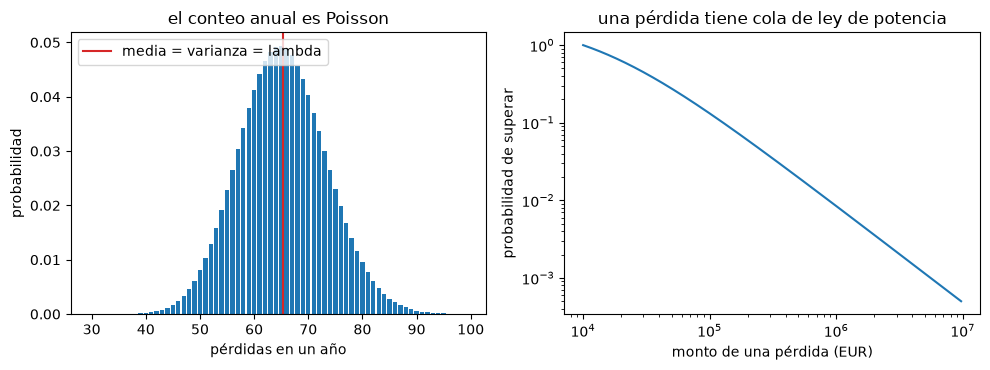

In [5]:
# Dibujar el conteo Poisson de un año y la supervivencia de una pérdida, ambos con el motor
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.bar(k[30:100], pmf[30:100], color="tab:blue")
left.axvline(lam, color="tab:red", label="media = varianza = lambda")
left.set_xlabel("pérdidas en un año")
left.set_ylabel("probabilidad")
left.set_title("el conteo anual es Poisson")
left.legend(loc="upper left")
levels_grid = np.linspace(0.001, 0.9995, 400)
sizes_grid = distributions.severity_ppf("gpd", sev_params, levels_grid)
right.loglog(sizes_grid, 1 - levels_grid, color="tab:blue")
right.set_xlabel("monto de una pérdida (EUR)")
right.set_ylabel("probabilidad de superar")
right.set_title("una pérdida tiene cola de ley de potencia")
fig.tight_layout()
plt.show()

El panel izquierdo es una campana alrededor de 65 pérdidas: el conteo de un año es casi el mismo cada año, con P(N = 65) = 0,0494 en el máximo y casi nada bajo 45 o sobre 85. El panel derecho es lo contrario: en ejes logarítmicos la supervivencia de una pérdida es casi una recta, la firma de una ley de potencia, de modo que una pérdida entre mil ya cuesta EUR 5.559.249 y nada en los datos la acota. El conteo es manso y el monto es salvaje, y por eso el capital lo decide la severidad. Los paneles no muestran cómo se combinan ambos en un año.

### Paso 3: un año a mano

Para ver la suma compuesta en acción, sortea el conteo de un año, luego tantos montos, y súmalos. Los montos se sortean por el método de la inversa: un número uniforme en $(0, 1)$ pasa por la función cuantil del motor. La celda siguiente lo hace para cinco años con una semilla fija e imprime, en cada año, cuántas pérdidas hubo, la mayor y el total. Es una ilustración de la definición; la simulación del propio motor, en el paso siguiente, es el método.

In [6]:
# Cinco años simulados a mano: un conteo de Poisson, y luego esa cantidad de tamaños por la función de cuantiles del
# motor
rng = np.random.default_rng(2026)
for year in range(1, 6):
    n_losses = int(rng.poisson(lam))
    sizes = distributions.severity_ppf("gpd", sev_params, rng.random(n_losses))
    print("año %d: N = %d | pérdida mayor EUR %s | Z = EUR %s | participación de la mayor en Z %.2f" %
          (year, n_losses, format(sizes.max(), ",.0f"), format(sizes.sum(), ",.0f"), sizes.max() / sizes.sum()))

año 1: N = 57 | pérdida mayor EUR 327,256 | Z = EUR 2,509,325 | participación de la mayor en Z 0.13
año 2: N = 73 | pérdida mayor EUR 852,626 | Z = EUR 4,528,061 | participación de la mayor en Z 0.19
año 3: N = 58 | pérdida mayor EUR 487,512 | Z = EUR 3,284,439 | participación de la mayor en Z 0.15
año 4: N = 69 | pérdida mayor EUR 1,258,753 | Z = EUR 6,579,399 | participación de la mayor en Z 0.19
año 5: N = 57 | pérdida mayor EUR 8,803,008 | Z = EUR 11,660,842 | participación de la mayor en Z 0.75


### Paso 4: muchos años con el motor

`simulate_annual_losses` hace exactamente esto para tantos años como pidas, de forma determinista para una semilla: los conteos de todos los años salen de una corriente aleatoria y los montos de una segunda, y el resultado no depende de cómo se parta el trabajo. La celda siguiente simula 100.000 años y compara la media muestral de $Z$ con su valor exacto $E[Z] = \lambda\, E[X]$ de `compound_poisson_moments`. La varianza exacta es infinita, así que la media muestral converge despacio.

In [7]:
# Simular 100.000 años y comparar la media muestral con la media exacta de la suma compuesta
SEED = 17
sample = aggregate.simulate_annual_losses("poisson", (lam,), "gpd", sev_params, 100_000, SEED)
exact = aggregate.compound_poisson_moments(lam, "gpd", sev_params)
print("años simulados:", sample.n_years, "| semilla:", sample.seed)
print("media muestral de Z (EUR):", format(sample.losses.mean(), ",.0f"))
print("media exacta de Z (EUR):", format(exact.mean, ",.0f"), "| varianza exacta:", exact.variance)
print("años sin pérdida:", int((sample.losses == 0).sum()), "| año mayor EUR", format(sample.losses.max(), ",.0f"))

años simulados: 100000 | semilla: 17
media muestral de Z (EUR): 6,180,404
media exacta de Z (EUR): 6,444,989 | varianza exacta: inf
años sin pérdida: 0 | año mayor EUR 4,445,754,408


### Paso 5: el cuantil de 99,9% y su error

El capital es el cuantil de 99,9% de $Z$: la pérdida que se supera una vez cada mil años. Desde $K$ años simulados, `mc_quantile` devuelve el estadístico de orden de rango $\lceil K \alpha \rceil$ y un error estándar a partir de la dispersión binomial del rango, con $s = \sqrt{K \alpha (1 - \alpha)}$ (Shevchenko, 2010: el error decae como $K^{-1/2}$). Con $\alpha = 0,999$ solo $K / 1000$ años simulados quedan sobre el cuantil, así que la estimación descansa en muy pocos puntos. La celda siguiente estima el cuantil con 10.000, 100.000 y 1.000.000 de años.

In [8]:
# El cuantil de Monte Carlo y su error estándar con tres tamaños de simulación
rows = []
for n_years in (10_000, 100_000, 1_000_000):
    losses = aggregate.simulate_annual_losses("poisson", (lam,), "gpd", sev_params, n_years, SEED).losses
    q, se = aggregate.mc_quantile(losses, 0.999)
    rows.append((n_years, q, se))
    print("años %9d | años sobre el cuantil %5d | q = EUR %s | error estándar EUR %s (%.1f%%)" %
          (n_years, n_years // 1000, format(q, ",.0f"), format(se, ",.0f"), 100 * se / q))

años     10000 | años sobre el cuantil    10 | q = EUR 142,539,576 | error estándar EUR 63,069,007 (44.2%)
años    100000 | años sobre el cuantil   100 | q = EUR 157,369,474 | error estándar EUR 13,605,077 (8.6%)
años   1000000 | años sobre el cuantil  1000 | q = EUR 163,999,415 | error estándar EUR 4,936,818 (3.0%)


### Paso 6: el valor verdadero

El caso versiona el cuantil de 99,9% verdadero de esta variante, calculado una vez con el método de Fourier del motor sobre una grilla fina y verificado con un Monte Carlo de 10.000.000 de años (los notebooks siguientes de este tema enseñan esos métodos). La celda siguiente lo lee, pone nuestras tres estimaciones a su lado en unidades de su propio error estándar.

In [9]:
# Comparar las tres estimaciones con el cuantil verdadero versionado
true_q = truth["annual_loss_quantile"]["value_eur"]
check = truth["annual_loss_quantile"]["mc_check"]
print(
    "cuantil verdadero (%s, paso de grilla EUR %d): EUR %s" % (
        truth["annual_loss_quantile"]["method"], truth["annual_loss_quantile"]["grid_step_eur"],
        format(true_q, ",.0f")
    )
)
print(
    "Monte Carlo versionado (%d años): EUR %s +/- %s" % (
        check["n_years"], format(check["value_eur"], ",.0f"), format(check["standard_error_eur"], ",.0f")
    )
)
for n_years, q, se in rows:
    print(
        "años %9d: razón a la verdad %.3f | distancia en errores estándar %+.2f" % (
            n_years, q / true_q, (q - true_q) / se
        )
    )

cuantil verdadero (fft, paso de grilla EUR 1000): EUR 163,483,000
Monte Carlo versionado (10000000 años): EUR 162,770,645 +/- 1,238,015
años     10000: razón a la verdad 0.872 | distancia en errores estándar -0.33
años    100000: razón a la verdad 0.963 | distancia en errores estándar -0.45
años   1000000: razón a la verdad 1.003 | distancia en errores estándar +0.10


La última celda dibuja las dos lecciones. A la izquierda, la distribución de la pérdida anual simulada en un eje logarítmico: la mayoría de los años son pequeños y unos pocos son enormes, por lo que el cuantil de 99,9% queda lejos de la media. A la derecha, las tres estimaciones Monte Carlo con sus errores estándar frente al valor verdadero: más años estrechan la banda de error, despacio.

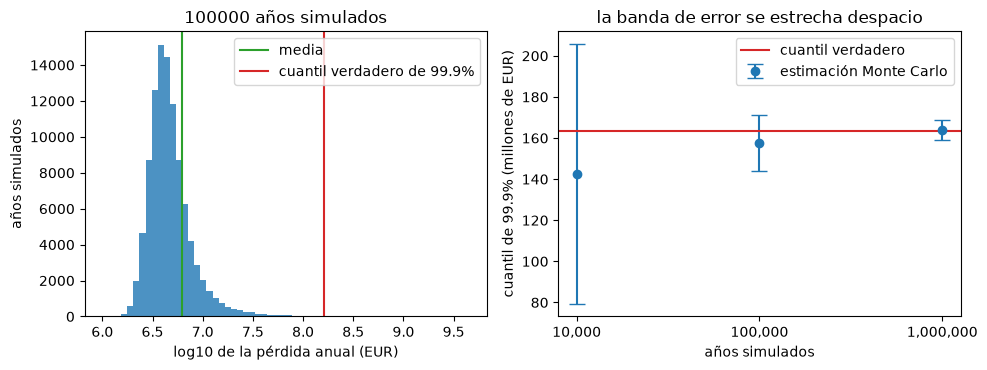

In [10]:
# Dibujar la distribución de la pérdida anual y las estimaciones de Monte Carlo contra la verdad
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
log_losses = np.log10(sample.losses[sample.losses > 0])
left.hist(log_losses, bins=60, color="tab:blue", alpha=0.8)
left.axvline(np.log10(sample.losses.mean()), color="tab:green", label="media")
left.axvline(np.log10(true_q), color="tab:red", label="cuantil verdadero de 99.9%")
left.set_xlabel("log10 de la pérdida anual (EUR)")
left.set_ylabel("años simulados")
left.set_title("100000 años simulados")
left.legend()

sizes = [r[0] for r in rows]
right.errorbar(
    range(len(rows)), [r[1] / 1e6 for r in rows], yerr=[r[2] / 1e6 for r in rows], fmt="o", capsize=6,
    label="estimación Monte Carlo"
)
right.axhline(true_q / 1e6, color="tab:red", label="cuantil verdadero")
right.set_xticks(range(len(rows)))
right.set_xticklabels([format(n, ",") for n in sizes])
right.set_xlabel("años simulados")
right.set_ylabel("cuantil de 99.9% (millones de EUR)")
right.set_title("la banda de error se estrecha despacio")
right.legend()
fig.tight_layout()
plt.show()

A la izquierda, el histograma de 100.000 años simulados tiene un hombro derecho largo: la mayoría de los años cuesta unos pocos millones de euro y un puñado supera los cien millones, de modo que la línea roja del cuantil verdadero queda muy a la derecha de la media verde. A la derecha, cada estimación cae a menos de un error estándar de la verdad y las barras se acortan al crecer los años, pero despacio, en un factor cercano a 13 por cien veces más años. La figura no muestra que otra semilla movería la estimación de 10.000 años en decenas de millones.

## Resultados

**Respuesta:** El banco sintético sufre 65,2849 pérdidas al año sobre EUR 10.000, y el cuantil verdadero de 99,9% de su pérdida anual, el capital, es EUR 163.483.000. Un Monte Carlo de 10.000 años simulados estima EUR 142.539.576 con un error estándar de 44,2%, 100.000 años dan EUR 157.369.474 (8,6%) y 1.000.000 de años dan EUR 163.999.415 (3,0%): un capital con error de pocos por ciento exige cerca de un millón de años simulados.

- **Frecuencia y severidad.** El banco sufre unas 65,28 pérdidas al año de EUR 10.000 o más. Una pérdida tiene una mediana de EUR 26.438 y un cuantil de 99,9% de EUR 5,56 millones; su media es finita (EUR 98.721) y su segundo momento es infinito, porque el índice de cola 0,8 por 2 supera 1.
- **La suma compuesta.** Cinco años sorteados a mano dan totales desde EUR 2,5 millones hasta EUR 11,7 millones, y en el año 5 una sola pérdida es el 75% del total. Con 100.000 años simulados la media muestral es EUR 6,18 millones frente a los EUR 6,44 millones exactos, 4% por debajo, y el año mayor simulado es de EUR 4,4 mil millones, unas 690 veces la media. Con varianza infinita, hasta la media tarda en asentarse.
- **El cuantil.** Las estimaciones de 99,9% son EUR 142,5 millones, 157,4 millones y 164,0 millones con 10.000, 100.000 y 1.000.000 de años, con errores estándar de 44%, 8,6% y 3,0% de la estimación. El cuantil verdadero versionado es EUR 163,48 millones, y el Monte Carlo versionado de 10.000.000 de años da EUR 162,77 millones con un error estándar de EUR 1,24 millones. Cada una de nuestras estimaciones queda a menos de un error estándar de la verdad. Cien veces más años reducen el error en un factor cercano a 13, no a 100: el error decae como la raíz cuadrada del número de años.

Lo que este notebook no muestra: cómo el motor calcula la distribución exacta en vez de simularla (notebook 03), qué cambia cuando el banco registra solo las pérdidas sobre un umbral (notebook 02) y la aproximación de forma cerrada del cuantil (notebook 04).

## Resumen

- La pérdida operacional anual es una suma compuesta: un número Poisson de pérdidas, cada una con un monto Pareto generalizado, sumadas.
- Con un índice de cola cercano a 1, unas pocas pérdidas explican la mayor parte de un mal año, la varianza puede ser infinita y hasta la media converge despacio.
- El capital es un cuantil de 99,9% de la pérdida anual; una estimación Monte Carlo descansa en un año de cada mil de la simulación y su error estándar cae como la raíz cuadrada del número de años.
- El caso versiona el cuantil verdadero porque el generador es conocido, así que toda estimación de capital de los notebooks siguientes se puede juzgar frente a él.

**Qué probar a continuación.** Cambia `SEED` y mira cómo la estimación con 10.000 años se mueve decenas de millones de euros mientras la de 1.000.000 de años casi no se mueve. Luego carga `xi-1-1.json`, cuyo índice de cola es 1,1, y pide al motor `compound_poisson_moments`: la media es infinita. Sigue con el notebook 02.

## Referencias

- BCBS (2009), Results from the 2008 Loss Data Collection Exercise for Operational Risk, Comité de Supervisión Bancaria de Basilea. https://www.bis.org/publ/bcbs160.htm
- Shevchenko, P. V. (2010), Calculation of aggregate loss distributions, Journal of Operational Risk 5(2), 3-40. https://arxiv.org/abs/1008.1108 y https://doi.org/10.21314/JOP.2010.077